In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [3]:
encounters = pd.read_csv(r"C:\Users\HP\Desktop\healthcare-operations-predictive-model\data\raw\encounters.csv")
patients = pd.read_csv(r"C:\Users\HP\Desktop\healthcare-operations-predictive-model\data\raw\patients.csv")
procedures = pd.read_csv(r"C:\Users\HP\Desktop\healthcare-operations-predictive-model\data\raw\procedures.csv")
payers = pd.read_csv(r"C:\Users\HP\Desktop\healthcare-operations-predictive-model\data\raw\payers.csv")
organizations = pd.read_csv(r"C:\Users\HP\Desktop\healthcare-operations-predictive-model\data\raw\organizations.csv")
data_dictionary = pd.read_csv(r"C:\Users\HP\Desktop\healthcare-operations-predictive-model\data\raw\data_dictionary.csv")

In [4]:
# Inspect the encounters dataset
display(encounters.head())

print("Shape:", encounters.shape)
print("\nColumns:")
print(encounters.columns.tolist())

print("\nDataset information:")
encounters.info()

print("\nMissing values:")
display(encounters.isnull().sum())

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02T09:26:36Z,2011-01-02T12:58:36Z,3de74169-7f67-9304-91d4-757e0f3a14d2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185347001,Encounter for problem (procedure),85.55,1018.02,0.00,NaN,NaN
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03T05:44:39Z,2011-01-03T06:01:42Z,d9ec2e44-32e9-9148-179a-1653348cc4e2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,308335008,Patient encounter procedure,142.58,2619.36,0.00,NaN,NaN
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03T14:32:11Z,2011-01-03T14:47:11Z,73babadf-5b2b-fee7-189e-6f41ff213e01,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,outpatient,185349003,Encounter for check up (procedure),85.55,461.59,305.27,NaN,NaN
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03T16:24:45Z,2011-01-03T16:39:45Z,3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,1784.24,0.00,NaN,NaN
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03T17:36:53Z,2011-01-03T17:51:53Z,fa006887-d93c-d302-8b89-f3c25f88c0e1,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,ambulatory,390906007,Follow-up encounter,85.55,234.72,0.00,55822004.0,Hyperlipidemia


Shape: (27891, 14)

Columns:
['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27891 entries, 0 to 27890
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   27891 non-null  object 
 1   START                27891 non-null  object 
 2   STOP                 27891 non-null  object 
 3   PATIENT              27891 non-null  object 
 4   ORGANIZATION         27891 non-null  object 
 5   PAYER                27891 non-null  object 
 6   ENCOUNTERCLASS       27891 non-null  object 
 7   CODE                 27891 non-null  int64  
 8   DESCRIPTION          27891 non-null  object 
 9   BASE_ENCOUNTER_COST  27891 non-null  float64
 10  TOTAL_CLAIM_COST     27891 non-null  f

Id                         0
START                      0
STOP                       0
PATIENT                    0
ORGANIZATION               0
PAYER                      0
ENCOUNTERCLASS             0
CODE                       0
DESCRIPTION                0
BASE_ENCOUNTER_COST        0
TOTAL_CLAIM_COST           0
PAYER_COVERAGE             0
REASONCODE             19541
REASONDESCRIPTION      19541
dtype: int64

count    2.789100e+04
mean     4.359597e+02
std      2.389942e+04
min      1.500000e+01
25%      1.500000e+01
50%      1.500000e+01
75%      5.185000e+01
max      2.695800e+06
Name: DURATION_MINUTES, dtype: float64

Zero or negative durations: 0


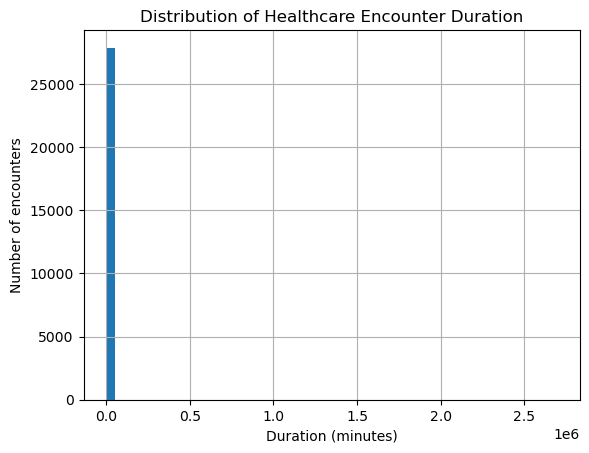

In [5]:
# Convert timestamps to datetime
encounters["START"] = pd.to_datetime(encounters["START"], utc=True)
encounters["STOP"] = pd.to_datetime(encounters["STOP"], utc=True)

# Calculate encounter duration in minutes
encounters["DURATION_MINUTES"] = (
    encounters["STOP"] - encounters["START"]
).dt.total_seconds() / 60

# Inspect duration
display(encounters["DURATION_MINUTES"].describe())

# Check invalid durations
print("Zero or negative durations:",
      (encounters["DURATION_MINUTES"] <= 0).sum())

# Visualize distribution
import matplotlib.pyplot as plt

encounters["DURATION_MINUTES"].hist(bins=50)
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of encounters")
plt.title("Distribution of Healthcare Encounter Duration")
plt.show()

In [6]:
datasets = {
    "Patients": patients,
    "Procedures": procedures,
    "Payers": payers,
    "Organizations": organizations,
    "Data Dictionary": data_dictionary
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())


Patients
Shape: (974, 20)
Columns: ['Id', 'BIRTHDATE', 'DEATHDATE', 'PREFIX', 'FIRST', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON']

Procedures
Shape: (47701, 9)
Columns: ['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'BASE_COST', 'REASONCODE', 'REASONDESCRIPTION']

Payers
Shape: (10, 7)
Columns: ['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE_HEADQUARTERED', 'ZIP', 'PHONE']

Organizations
Shape: (1, 8)
Columns: ['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE', 'ZIP', 'LAT', 'LON']

Data Dictionary
Shape: (65, 3)
Columns: ['Table', 'Field', 'Description']


In [7]:
longest = encounters.nlargest(15, "DURATION_MINUTES")[
    ["START", "STOP", "ENCOUNTERCLASS",
     "DESCRIPTION", "DURATION_MINUTES"]
]

display(longest)

print("Over 24 hours:",
      (encounters["DURATION_MINUTES"] > 1440).sum())

print("Over 7 days:",
      (encounters["DURATION_MINUTES"] > 10080).sum())

print("Over 30 days:",
      (encounters["DURATION_MINUTES"] > 43200).sum())

,START,STOP,ENCOUNTERCLASS,DESCRIPTION,DURATION_MINUTES
9704,2014-12-17 11:49:08+00:00,2020-02-01 13:49:08+00:00,ambulatory,Follow-up encounter (procedure),2.695800e+06
7735,2014-03-27 00:33:14+00:00,2019-03-13 15:33:14+00:00,ambulatory,Follow-up encounter (procedure),2.610180e+06
7805,2014-04-02 22:26:28+00:00,2015-07-02 13:44:57+00:00,ambulatory,Follow-up encounter (procedure),6.561185e+05
6116,2014-01-31 02:29:54+00:00,2015-04-22 02:29:54+00:00,outpatient,Encounter for problem (procedure),6.422400e+05
6371,2014-02-06 02:17:34+00:00,2015-01-20 02:17:34+00:00,outpatient,Encounter for problem (procedure),5.011200e+05
18343,2018-07-18 23:56:20+00:00,2019-06-27 17:56:35+00:00,inpatient,Periodic reevaluation and management of health...,4.950002e+05
6380,2014-02-06 04:57:58+00:00,2015-01-13 04:57:58+00:00,outpatient,Encounter for problem (procedure),4.910400e+05
7832,2014-04-04 22:41:46+00:00,2015-01-31 13:54:32+00:00,ambulatory,Follow-up encounter (procedure),4.343528e+05
6125,2014-01-31 11:10:57+00:00,2014-06-25 11:10:57+00:00,outpatient,Encounter for problem (procedure),2.088000e+05
6138,2014-01-31 20:39:04+00:00,2014-04-09 20:39:04+00:00,outpatient,Encounter for problem (procedure),9.792000e+04


Over 24 hours: 75
Over 7 days: 31
Over 30 days: 13


In [8]:
duration_by_class = encounters.groupby("ENCOUNTERCLASS")[
    "DURATION_MINUTES"
].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(duration_by_class)

,count,mean,median,min,max
ENCOUNTERCLASS,,,,,
ambulatory,12537,568.77,15.0,15.0,2695800.00
emergency,2322,92.51,60.0,60.0,35340.00
inpatient,1135,2210.50,1440.0,1440.0,495000.25
outpatient,6300,352.55,15.0,15.0,642240.00
urgentcare,3666,15.00,15.0,15.0,15.00
wellness,1931,15.00,15.0,15.0,15.00


In [9]:
percentiles = encounters["DURATION_MINUTES"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 1.00]
)

display(percentiles)

0.500         15.00
0.750         51.85
0.900        168.00
0.950        228.00
0.990       1440.00
0.995       1440.00
1.000    2695800.00
Name: DURATION_MINUTES, dtype: float64

In [10]:
long_encounters = encounters[
    encounters["DURATION_MINUTES"] > 1440
]

display(
    long_encounters.groupby("ENCOUNTERCLASS")
    ["DURATION_MINUTES"]
    .agg(["count", "median", "max"])
    .sort_values("count", ascending=False)
)

,count,median,max
ENCOUNTERCLASS,,,
inpatient,58,3720.916667,495000.25
outpatient,7,208800.000000,642240.00
ambulatory,5,656118.483333,2695800.00
emergency,5,7440.000000,35340.00


In [11]:
very_long = encounters[
    encounters["DURATION_MINUTES"] > 43200
]

display(
    very_long[
        ["START", "STOP", "ENCOUNTERCLASS",
         "DESCRIPTION", "DURATION_MINUTES"]
    ]
)

,START,STOP,ENCOUNTERCLASS,DESCRIPTION,DURATION_MINUTES
6116,2014-01-31 02:29:54+00:00,2015-04-22 02:29:54+00:00,outpatient,Encounter for problem (procedure),6.422400e+05
6125,2014-01-31 11:10:57+00:00,2014-06-25 11:10:57+00:00,outpatient,Encounter for problem (procedure),2.088000e+05
6138,2014-01-31 20:39:04+00:00,2014-04-09 20:39:04+00:00,outpatient,Encounter for problem (procedure),9.792000e+04
6145,2014-01-31 23:35:27+00:00,2014-03-26 23:35:27+00:00,outpatient,Encounter for problem (procedure),7.776000e+04
6332,2014-02-05 08:41:28+00:00,2014-04-14 08:41:28+00:00,outpatient,Encounter for problem (procedure),9.792000e+04
6371,2014-02-06 02:17:34+00:00,2015-01-20 02:17:34+00:00,outpatient,Encounter for problem (procedure),5.011200e+05
6380,2014-02-06 04:57:58+00:00,2015-01-13 04:57:58+00:00,outpatient,Encounter for problem (procedure),4.910400e+05
7735,2014-03-27 00:33:14+00:00,2019-03-13 15:33:14+00:00,ambulatory,Follow-up encounter (procedure),2.610180e+06
7805,2014-04-02 22:26:28+00:00,2015-07-02 13:44:57+00:00,ambulatory,Follow-up encounter (procedure),6.561185e+05
7832,2014-04-04 22:41:46+00:00,2015-01-31 13:54:32+00:00,ambulatory,Follow-up encounter (procedure),4.343528e+05


In [12]:
long_encounters = encounters[
    encounters["DURATION_MINUTES"] > 1440
].copy()

long_encounters["START_YEAR"] = (
    long_encounters["START"].dt.year
)

display(
    long_encounters.groupby(
        ["START_YEAR", "ENCOUNTERCLASS"]
    ).size().unstack(fill_value=0)
)

ENCOUNTERCLASS,ambulatory,emergency,inpatient,outpatient
START_YEAR,,,,
2011,0,1,2,0
2013,0,1,5,0
2014,5,0,5,7
2015,0,0,4,0
2017,0,1,4,0
2018,0,1,4,0
2020,0,1,22,0
2021,0,0,12,0


In [13]:
inpatient = encounters[
    encounters["ENCOUNTERCLASS"] == "inpatient"
]

display(
    inpatient["DURATION_MINUTES"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Examine inpatient encounters lasting more than 7 days
display(
    inpatient[
        inpatient["DURATION_MINUTES"] > 10080
    ][
        ["START", "STOP", "DESCRIPTION", "DURATION_MINUTES"]
    ].sort_values("DURATION_MINUTES", ascending=False)
)

count      1135.000000
mean       2210.495154
std       14948.841890
min        1440.000000
50%        1440.000000
75%        1440.000000
90%        1440.000000
95%        1477.648333
99%       13223.682000
max      495000.250000
Name: DURATION_MINUTES, dtype: float64

,START,STOP,DESCRIPTION,DURATION_MINUTES
18343,2018-07-18 23:56:20+00:00,2019-06-27 17:56:35+00:00,Periodic reevaluation and management of health...,495000.250000
16504,2017-09-30 13:44:27+00:00,2017-11-25 13:44:27+00:00,Periodic reevaluation and management of health...,80640.000000
5457,2013-10-22 00:16:17+00:00,2013-11-14 00:16:17+00:00,Encounter for symptom (procedure),33120.000000
24226,2021-01-12 14:24:46+00:00,2021-01-25 15:06:45+00:00,Hospital admission for isolation (procedure),18761.983333
24155,2021-01-03 03:22:46+00:00,2021-01-16 04:02:42+00:00,Hospital admission for isolation (procedure),18759.933333
23972,2020-12-12 19:05:25+00:00,2020-12-25 19:32:34+00:00,Hospital admission for isolation (procedure),18747.150000
23778,2020-11-18 17:21:42+00:00,2020-12-01 17:42:27+00:00,Hospital admission for isolation (procedure),18740.750000
23567,2020-10-25 08:06:34+00:00,2020-11-06 08:36:59+00:00,Hospital admission for isolation (procedure),17310.416667
22927,2020-07-29 08:16:01+00:00,2020-08-10 08:32:32+00:00,Hospital admission for isolation (procedure),17296.516667
25310,2021-04-08 22:38:43+00:00,2021-04-19 23:02:15+00:00,Hospital admission for isolation (procedure),15863.533333


In [14]:
display(
    encounters[
        encounters["DURATION_MINUTES"] > 10080
    ][
        [
            "ENCOUNTERCLASS",
            "DESCRIPTION",
            "DURATION_MINUTES",
            "BASE_ENCOUNTER_COST",
            "TOTAL_CLAIM_COST",
            "PAYER_COVERAGE"
        ]
    ].sort_values("DURATION_MINUTES", ascending=False)
)

,ENCOUNTERCLASS,DESCRIPTION,DURATION_MINUTES,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE
9704,ambulatory,Follow-up encounter (procedure),2.695800e+06,85.55,85.55,0.00
7735,ambulatory,Follow-up encounter (procedure),2.610180e+06,85.55,85.55,7.91
7805,ambulatory,Follow-up encounter (procedure),6.561185e+05,85.55,85.55,24.27
6116,outpatient,Encounter for problem (procedure),6.422400e+05,85.55,85.55,36.44
6371,outpatient,Encounter for problem (procedure),5.011200e+05,85.55,85.55,0.00
18343,inpatient,Periodic reevaluation and management of health...,4.950002e+05,146.18,7093.85,5643.08
6380,outpatient,Encounter for problem (procedure),4.910400e+05,85.55,85.55,0.00
7832,ambulatory,Follow-up encounter (procedure),4.343528e+05,85.55,85.55,0.00
6125,outpatient,Encounter for problem (procedure),2.088000e+05,85.55,85.55,0.00
6138,outpatient,Encounter for problem (procedure),9.792000e+04,85.55,85.55,36.44


In [15]:
suspect = encounters[
    (encounters["DURATION_MINUTES"] > 43200) &
    (
        encounters["ENCOUNTERCLASS"].isin(
            ["ambulatory", "outpatient"]
        ) |
        encounters["DESCRIPTION"].str.contains(
            "Periodic reevaluation",
            case=False,
            na=False
        )
    )
]

print("Suspected records:", len(suspect))

display(
    suspect[
        [
            "ENCOUNTERCLASS",
            "DESCRIPTION",
            "START",
            "STOP",
            "DURATION_MINUTES"
        ]
    ]
)

Suspected records: 13


,ENCOUNTERCLASS,DESCRIPTION,START,STOP,DURATION_MINUTES
6116,outpatient,Encounter for problem (procedure),2014-01-31 02:29:54+00:00,2015-04-22 02:29:54+00:00,6.422400e+05
6125,outpatient,Encounter for problem (procedure),2014-01-31 11:10:57+00:00,2014-06-25 11:10:57+00:00,2.088000e+05
6138,outpatient,Encounter for problem (procedure),2014-01-31 20:39:04+00:00,2014-04-09 20:39:04+00:00,9.792000e+04
6145,outpatient,Encounter for problem (procedure),2014-01-31 23:35:27+00:00,2014-03-26 23:35:27+00:00,7.776000e+04
6332,outpatient,Encounter for problem (procedure),2014-02-05 08:41:28+00:00,2014-04-14 08:41:28+00:00,9.792000e+04
6371,outpatient,Encounter for problem (procedure),2014-02-06 02:17:34+00:00,2015-01-20 02:17:34+00:00,5.011200e+05
6380,outpatient,Encounter for problem (procedure),2014-02-06 04:57:58+00:00,2015-01-13 04:57:58+00:00,4.910400e+05
7735,ambulatory,Follow-up encounter (procedure),2014-03-27 00:33:14+00:00,2019-03-13 15:33:14+00:00,2.610180e+06
7805,ambulatory,Follow-up encounter (procedure),2014-04-02 22:26:28+00:00,2015-07-02 13:44:57+00:00,6.561185e+05
7832,ambulatory,Follow-up encounter (procedure),2014-04-04 22:41:46+00:00,2015-01-31 13:54:32+00:00,4.343528e+05


In [16]:
print("Original records:", len(encounters))
print("Suspected anomalies:", len(suspect))
print("Remaining records:", len(encounters) - len(suspect))

Original records: 27891
Suspected anomalies: 13
Remaining records: 27878


In [17]:
long_encounters = encounters[
    (encounters["DURATION_MINUTES"] > 7 * 24 * 60) &
    (~encounters.index.isin(suspect.index))
]

long_encounters[
    [
        "START",
        "STOP",
        "ENCOUNTERCLASS",
        "DESCRIPTION",
        "DURATION_MINUTES",
        "BASE_ENCOUNTER_COST",
        "TOTAL_CLAIM_COST"
    ]
].sort_values("DURATION_MINUTES", ascending=False)

,START,STOP,ENCOUNTERCLASS,DESCRIPTION,DURATION_MINUTES,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST
8980,2014-09-14 10:42:36+00:00,2014-10-11 21:42:36+00:00,ambulatory,Follow-up encounter (procedure),39540.000000,85.55,85.55
23048,2020-08-15 04:52:21+00:00,2020-09-08 17:52:21+00:00,emergency,Encounter for problem,35340.000000,87.71,641882.70
5457,2013-10-22 00:16:17+00:00,2013-11-14 00:16:17+00:00,inpatient,Encounter for symptom (procedure),33120.000000,87.71,7664.97
14807,2017-01-11 09:03:19+00:00,2017-01-27 09:03:19+00:00,emergency,Emergency room admission (procedure),23040.000000,146.18,1036.94
24226,2021-01-12 14:24:46+00:00,2021-01-25 15:06:45+00:00,inpatient,Hospital admission for isolation (procedure),18761.983333,146.18,22821.65
24155,2021-01-03 03:22:46+00:00,2021-01-16 04:02:42+00:00,inpatient,Hospital admission for isolation (procedure),18759.933333,146.18,21146.49
23972,2020-12-12 19:05:25+00:00,2020-12-25 19:32:34+00:00,inpatient,Hospital admission for isolation (procedure),18747.150000,146.18,25195.93
23778,2020-11-18 17:21:42+00:00,2020-12-01 17:42:27+00:00,inpatient,Hospital admission for isolation (procedure),18740.750000,146.18,26875.55
23567,2020-10-25 08:06:34+00:00,2020-11-06 08:36:59+00:00,inpatient,Hospital admission for isolation (procedure),17310.416667,146.18,21923.13
22927,2020-07-29 08:16:01+00:00,2020-08-10 08:32:32+00:00,inpatient,Hospital admission for isolation (procedure),17296.516667,146.18,21318.60


In [18]:
investigate_ids = [8980, 23048, 5457, 14807]

for encounter_id in investigate_ids:
    print(f"\nEncounter ID: {encounters.loc[encounter_id, 'Id']}")
    print("Description:", encounters.loc[encounter_id, "DESCRIPTION"])

    related = procedures[
        procedures["ENCOUNTER"] == encounters.loc[encounter_id, "Id"]
    ]

    print("Number of procedures:", len(related))
    print(related[["DESCRIPTION", "BASE_COST"]].head(10))


Encounter ID: 9741be00-49a5-f25a-a59b-ea46ffbad229
Description: Follow-up encounter (procedure)
Number of procedures: 0
Empty DataFrame
Columns: [DESCRIPTION, BASE_COST]
Index: []

Encounter ID: 6c108963-2fda-815b-3813-a424b3533127
Description: Encounter for problem
Number of procedures: 10
                                             DESCRIPTION  BASE_COST
41088  Resuscitation using intravenous fluid (procedure)        431
41089                           Admit to ICU (procedure)     289531
41090  Resuscitation using intravenous fluid (procedure)        431
41113              Transfer to stepdown unit (procedure)        431
41161                           Admit to ICU (procedure)     236283
41162  Resuscitation using intravenous fluid (procedure)        431
41188              Transfer to stepdown unit (procedure)        431
41269                           Admit to ICU (procedure)     112627
41271  Resuscitation using intravenous fluid (procedure)        431
41296              Transfer

In [19]:
excluded_ids = suspect.index.tolist() + [8980]

model_data = encounters.drop(index=excluded_ids).copy()

print("Original records:", len(encounters))
print("Excluded records:", len(excluded_ids))
print("Modelling records:", len(model_data))
print("\nDuration summary:")
print(model_data["DURATION_MINUTES"].describe())

Original records: 27891
Excluded records: 14
Modelling records: 27877

Duration summary:
count    27877.000000
mean       108.724755
std        570.874790
min         15.000000
25%         15.000000
50%         15.000000
75%         51.733333
max      35340.000000
Name: DURATION_MINUTES, dtype: float64


In [20]:
model_data[
    [
        "START",
        "ENCOUNTERCLASS",
        "CODE",
        "DESCRIPTION",
        "PATIENT",
        "PAYER",
        "BASE_ENCOUNTER_COST",
        "TOTAL_CLAIM_COST",
        "PAYER_COVERAGE",
        "REASONCODE",
        "REASONDESCRIPTION",
        "DURATION_MINUTES"
    ]
].head()

,START,ENCOUNTERCLASS,CODE,DESCRIPTION,PATIENT,PAYER,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION,DURATION_MINUTES
0,2011-01-02 09:26:36+00:00,ambulatory,185347001,Encounter for problem (procedure),3de74169-7f67-9304-91d4-757e0f3a14d2,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,85.55,1018.02,0.00,NaN,NaN,212.00
1,2011-01-03 05:44:39+00:00,outpatient,308335008,Patient encounter procedure,d9ec2e44-32e9-9148-179a-1653348cc4e2,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,142.58,2619.36,0.00,NaN,NaN,17.05
2,2011-01-03 14:32:11+00:00,outpatient,185349003,Encounter for check up (procedure),73babadf-5b2b-fee7-189e-6f41ff213e01,7caa7254-5050-3b5e-9eae-bd5ea30e809c,85.55,461.59,305.27,NaN,NaN,15.00
3,2011-01-03 16:24:45+00:00,wellness,162673000,General examination of patient (procedure),3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,136.80,1784.24,0.00,NaN,NaN,15.00
4,2011-01-03 17:36:53+00:00,ambulatory,390906007,Follow-up encounter,fa006887-d93c-d302-8b89-f3c25f88c0e1,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,85.55,234.72,0.00,55822004.0,Hyperlipidemia,15.00


In [21]:
print("Encounter classes:")
print(model_data["ENCOUNTERCLASS"].value_counts())

print("\nUnique encounter codes:", model_data["CODE"].nunique())
print("Unique payers:", model_data["PAYER"].nunique())

print("\nStart date range:")
print(model_data["START"].min())
print(model_data["START"].max())

Encounter classes:
ENCOUNTERCLASS
ambulatory    12532
outpatient     6293
urgentcare     3666
emergency      2322
wellness       1931
inpatient      1133
Name: count, dtype: int64

Unique encounter codes: 45
Unique payers: 10

Start date range:
2011-01-02 09:26:36+00:00
2022-02-05 20:27:36+00:00


In [22]:
# Create modelling features
data = model_data.copy()

data["START_YEAR"] = data["START"].dt.year
data["START_MONTH"] = data["START"].dt.month
data["START_DAY"] = data["START"].dt.day
data["START_HOUR"] = data["START"].dt.hour
data["START_DAYOFWEEK"] = data["START"].dt.dayofweek

features = [
    "ENCOUNTERCLASS",
    "CODE",
    "PAYER",
    "START_YEAR",
    "START_MONTH",
    "START_DAY",
    "START_HOUR",
    "START_DAYOFWEEK"
]

X = data[features]
y = data["DURATION_MINUTES"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nMissing feature values:")
print(X.isnull().sum())

Feature shape: (27877, 8)
Target shape: (27877,)

Missing feature values:
ENCOUNTERCLASS     0
CODE               0
PAYER              0
START_YEAR         0
START_MONTH        0
START_DAY          0
START_HOUR         0
START_DAYOFWEEK    0
dtype: int64


In [23]:
# Duplicate checks
datasets = {
    "encounters": encounters,
    "patients": patients,
    "procedures": procedures,
    "payers": payers,
    "organizations": organizations
}

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:", df.isnull().sum().sum())


ENCOUNTERS
Duplicate rows: 0
Missing values: 39082

PATIENTS
Duplicate rows: 0
Missing values: 2504

PROCEDURES
Duplicate rows: 0
Missing values: 73890

PAYERS
Duplicate rows: 0
Missing values: 5

ORGANIZATIONS
Duplicate rows: 0
Missing values: 0


In [24]:
# Check whether encounter patient IDs exist in patients
print(
    "Unmatched patient IDs:",
    (~encounters["PATIENT"].isin(patients["Id"])).sum()
)

# Check whether encounter payer IDs exist in payers
print(
    "Unmatched payer IDs:",
    (~encounters["PAYER"].isin(payers["Id"])).sum()
)

# Check whether encounter organisation IDs exist in organizations
print(
    "Unmatched organisation IDs:",
    (~encounters["ORGANIZATION"].isin(organizations["Id"])).sum()
)

# Check whether procedure encounter IDs exist in encounters
print(
    "Unmatched procedure encounter IDs:",
    (~procedures["ENCOUNTER"].isin(encounters["Id"])).sum()
)

Unmatched patient IDs: 0
Unmatched payer IDs: 0
Unmatched organisation IDs: 0
Unmatched procedure encounter IDs: 0


In [25]:
# Sort data by encounter start time
data_sorted = data.sort_values("START").copy()

X_sorted = data_sorted[features]
y_sorted = data_sorted["DURATION_MINUTES"]

# Split chronologically: 80% training, 20% testing
split_index = int(len(data_sorted) * 0.8)

X_train = X_sorted.iloc[:split_index]
X_test = X_sorted.iloc[split_index:]

y_train = y_sorted.iloc[:split_index]
y_test = y_sorted.iloc[split_index:]

# Display split information
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(data_sorted["START"].iloc[0], "to",
      data_sorted["START"].iloc[split_index - 1])

print("\nTesting period:")
print(data_sorted["START"].iloc[split_index], "to",
      data_sorted["START"].iloc[-1])

Training records: 22301
Testing records: 5576

Training period:
2011-01-02 09:26:36+00:00 to 2020-04-26 19:51:06+00:00

Testing period:
2020-04-26 21:05:51+00:00 to 2022-02-05 20:27:36+00:00


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline prediction: training median
baseline_prediction = np.full(
    shape=len(y_test),
    fill_value=y_train.median()
)

# Evaluate baseline
baseline_mae = mean_absolute_error(y_test, baseline_prediction)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_prediction))
baseline_r2 = r2_score(y_test, baseline_prediction)

print("Baseline prediction:", y_train.median(), "minutes")
print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2:", baseline_r2)

Baseline prediction: 15.0 minutes
Baseline MAE: 102.16142395982781
Baseline RMSE: 981.9438280914957
Baseline R2: -0.010942767077591009
